<a href="https://colab.research.google.com/github/maybsalty/Deep-Learning-CIFAR100-project/blob/main/Task%201/Sequential_Task1%20(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COMP 4930SEF Project

### Group Number: *Please write your group number here*
### Team Members & Student IDs: *Please write your names and 8-digit student IDs here*

## Introduction

In this project, we work on deep learning solutions across three tasks:

- **Task 1 (CIFAR-100 Subset Classification):** Designing, implementing, and evaluating three CNN models on the 50-class CIFAR-100 animals and people subset, and selecting the best model.
- **Task 2 (Group-Collected Image Classification):** Adapting the selected model from Task 1 to classify an image dataset collected by the group.
- **Task 3 (Text Analysis):** Applying text preprocessing and recurrent neural networks to a text classification or generation task.

In [12]:
%env TF_CPP_MIN_LOG_LEVEL=2

env: TF_CPP_MIN_LOG_LEVEL=2


## Task 1 - The Given Task (CIFAR-100 Subset Models)

### 1.1 Data Loading and Preprocessing

The CIFAR-100 subset keeps the 50 classes of animals and people (25,000 training examples and 5,000 test examples of size 32x32x3) and maps their labels to integers from 0 to 49.

The 25,000 training examples are split into 20,000 training examples and 5,000 validation examples (80% training set and 20% validation set), while the 5,000 test examples are used for evaluating the final selected model.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.datasets import cifar100
from sklearn.model_selection import train_test_split  # External code: stratified dataset splitting
from sklearn.metrics import classification_report  # External code: per-class precision/recall/F1 report

# Appendix: Code for loading the CIFAR-100 subset (Animals and People)
ANIMALS_PEOPLE_INDICES = [
    1, 2, 3, 4, 6, 7,
    11, 14, 15, 18, 19,
    21, 24, 26, 27, 29,
    30, 31, 32, 34, 35, 36, 38,
    42, 43, 44, 45, 46,
    50, 55, 57,
    63, 64, 65, 66, 67,
    72, 73, 74, 75, 77, 78, 79,
    80,
    91, 93, 95, 97, 98, 99,
]

# Returns a boolean mask for selecting animals/people in y
def select_animals_people(y):
    return np.isin(np.ravel(y), ANIMALS_PEOPLE_INDICES)

# Maps indices in y to range 0 to 49
def compress_animals_people_indices(y):
    out = np.zeros(100, dtype=np.int64)
    for i, index in enumerate(ANIMALS_PEOPLE_INDICES):
        out[index] = i
    return out[y]

# Loads a subset of CIFAR100 of animals and people
def load_cifar100_animals_people():
    keras.utils.set_random_seed(42)
    (X_train, y_train), (X_test, y_test) = cifar100.load_data()
    mask_train = select_animals_people(y_train)
    X_train, y_train = X_train[mask_train], y_train[mask_train]
    mask_test = select_animals_people(y_test)
    X_test, y_test = X_test[mask_test], y_test[mask_test]
    y_train = compress_animals_people_indices(y_train)
    y_test = compress_animals_people_indices(y_test)
    return X_train, y_train, X_test, y_test

In [14]:
# Load dataset and split into training, validation, and test sets
X_train_full, y_train_full, X_test, y_test = load_cifar100_animals_people()

# External code: stratified 80/20 train/validation split (reworked to Tutorial-Lecture variable naming)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2,
    random_state=42, stratify=y_train_full)

y_train = keras.utils.to_categorical(y_train, 50)  # one-hot encode
y_val = keras.utils.to_categorical(y_val, 50)
y_test = keras.utils.to_categorical(y_test, 50)

print(X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape)

(20000, 32, 32, 3) (20000, 50) (5000, 32, 32, 3) (5000, 50) (5000, 32, 32, 3) (5000, 50)


### 1.2 Utility Code, Regularization, and Data Augmentation

This section contains utility functions and shared components for training and evaluating the models:

- **Data augmentation:** Random horizontal flipping (`RandomFlip`), random rotation (`RandomRotation`), random spatial translation (`RandomTranslation`), and random zoom (`RandomZoom`).
- **Sequential backbone wrapper (`wrap_backbone`):** Wraps a pre-trained CNN backbone so its internal `BatchNormalization` layers remain in inference mode (`training=False`) inside `keras.Sequential`.
- **Two-stage transfer learning (`compile_and_fit_model`):**
  1. Freeze the pre-trained base model (`base_model.trainable = False`) and train the added layers with learning rate `1e-3` and label smoothing (`0.1`).
  2. Partially unfreeze the top 30 layers of the base model (keeping `BatchNormalization` layers frozen) and fine-tune with learning rate `5e-5` using early stopping, learning rate reduction, and model checkpointing.

In [15]:
final_values = {}

l2 = regularizers.l2(5e-4)  # Stronger L2 weight regularization (t06 style) to reduce overfitting

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),  # Random rotation augmentation (t09 style)
    layers.RandomTranslation(0.1, 0.1),  # External code: spatial shift augmentation
    layers.RandomZoom(0.1),  # External code: random zoom augmentation for scale invariance
], name="data_augmentation")

# Auto-generated: wrap pre-trained backbone so BatchNorm stays in inference mode inside keras.Sequential
def wrap_backbone(base_model):
    inputs = layers.Input(shape=base_model.input_shape[1:])
    outputs = base_model(inputs, training=False)
    return keras.Model(inputs=inputs, outputs=outputs, name=base_model.name)

# Retrieve final results in a training history
def history_final_values(history):
    # Auto-generated: supports combined dictionary returned by two-stage training
    hist = history.history if hasattr(history, "history") else history
    return {k: round(v[-1], 4) for k, v in hist.items()}

# Plot training history, including both training and validation results
def plot_history(history):
    # Auto-generated: supports combined dictionary returned by two-stage training
    hist = history.history if hasattr(history, "history") else history
    df = pd.DataFrame(hist)
    df.index = df.index + 1
    fig, axs = plt.subplots(1, 2, figsize=(8, 4))
    df.plot(y=["loss", "val_loss"], grid=True, ax=axs[0])
    df.plot(y=["acc", "val_acc"], grid=True, ax=axs[1])
    plt.tight_layout()

# Compile and fit a model using two-stage transfer learning, and return training history
def compile_and_fit_model(model, base_model, X_train, y_train, X_val, y_val,
                          save_path, warmup_epochs=6, finetune_epochs=14,
                          batch_size=128):
    fine_tune_layers = 30
    # External code: label smoothing prevents overconfident softmax predictions on training samples
    loss_fn = keras.losses.CategoricalCrossentropy(label_smoothing=0.1)

    # Stage 1: train new layers with frozen pre-trained base model
    base_model.trainable = False
    adam_opt = keras.optimizers.Adam(learning_rate=1e-3)
    model.compile(loss=loss_fn,
                  optimizer=adam_opt, metrics=["acc"])
    h1 = model.fit(X_train, y_train, epochs=warmup_epochs,
                   batch_size=batch_size, verbose=2,
                   validation_data=(X_val, y_val))

    # Auto-generated: Stage 2 partial fine-tuning loop (reworked into Tutorial-Lecture compile/fit style)
    base_model.trainable = True
    # External code: freeze early generic backbone layers and keep BatchNorm frozen to prevent overfitting
    for layer in base_model.layers[:-fine_tune_layers]:
        layer.trainable = False
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    adam_opt_ft = keras.optimizers.Adam(learning_rate=5e-5)
    model.compile(loss=loss_fn,
                  optimizer=adam_opt_ft, metrics=["acc"])
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3,
            restore_best_weights=True),  # External code: restore_best_weights option
        # External code: ReduceLROnPlateau and ModelCheckpoint aligned to minimum val_loss
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5,
            patience=2, min_lr=1e-6, verbose=1),
        keras.callbacks.ModelCheckpoint(
            save_path, monitor="val_loss",
            save_best_only=True, mode="min", verbose=1)
    ]
    h2 = model.fit(X_train, y_train, epochs=finetune_epochs,
                   batch_size=batch_size, verbose=2,
                   validation_data=(X_val, y_val),
                   callbacks=callbacks)

    # Auto-generated: combine Stage 1 and Stage 2 training histories
    combined_history = {k: h1.history[k] + h2.history[k] for k in h1.history}
    return combined_history

### 1.3 Attention Modules Beyond the Course (BAM & CBAM)

To improve feature extraction on the 50 fine-grained classes of animals and people, Models 2 and 3 add attention modules after the pre-trained CNN backbone:

1. **Convolutional Block Attention Module (CBAM):** Applies channel attention (using global average pooling, global max pooling, and shared dense layers) followed by spatial attention (using channel pooling and a 7x7 convolutional layer).
   - Reference: Woo, S., Park, J., Lee, J. Y., & Kweon, I. S. (2018). CBAM: Convolutional Block Attention Module. *Proceedings of the European Conference on Computer Vision (ECCV)*, 3-19.
2. **Bottleneck Attention Module (BAM):** Computes channel attention and dilated spatial attention in parallel, sums both outputs, applies `1 + sigmoid`, and multiplies with the input feature map.
   - Reference: Park, J., Woo, S., Lee, J. Y., & Kweon, I. S. (2018). BAM: Bottleneck Attention Module. *British Machine Vision Conference (BMVC)*.

In [16]:
# External code: BAM attention architecture (Park et al., 2018)
# Reworked into Tutorial-Lecture keras.Sequential-compatible layer block using standard keras.layers
def bam_block(input_shape, ratio=16, dilation_val=4):
    inputs = layers.Input(shape=input_shape)
    channels = inputs.shape[-1]
    reduced_channels = max(1, channels // ratio)

    # Channel branch
    c = layers.GlobalAveragePooling2D()(inputs)
    c = layers.Dense(reduced_channels, use_bias=True)(c)
    c = layers.BatchNormalization()(c)
    c = layers.Activation("relu")(c)
    c = layers.Dense(channels, use_bias=True)(c)
    channel_out = layers.Reshape((1, 1, channels))(c)

    # Spatial branch
    s = layers.Conv2D(reduced_channels, kernel_size=1, use_bias=False)(inputs)
    s = layers.BatchNormalization()(s)
    s = layers.Activation("relu")(s)
    s = layers.Conv2D(reduced_channels, kernel_size=3, padding="same",
                      dilation_rate=dilation_val, use_bias=False)(s)
    s = layers.BatchNormalization()(s)
    s = layers.Activation("relu")(s)
    s = layers.Conv2D(reduced_channels, kernel_size=3, padding="same",
                      dilation_rate=dilation_val, use_bias=False)(s)
    s = layers.BatchNormalization()(s)
    s = layers.Activation("relu")(s)
    spatial_out = layers.Conv2D(1, kernel_size=1, use_bias=False)(s)

    # Combine branches and scale input feature map
    att_logits = layers.Add()([channel_out, spatial_out])
    att_sig = layers.Activation("sigmoid")(att_logits)
    att_scaled = layers.Rescaling(scale=1.0, offset=1.0)(att_sig)
    outputs = layers.Multiply()([inputs, att_scaled])
    return keras.Model(inputs=inputs, outputs=outputs, name="bam_block")

In [17]:
# External code: CBAM attention architecture (Woo et al., 2018)
# Reworked into Tutorial-Lecture keras.Sequential-compatible layer block using standard keras.layers
def cbam_block(input_shape, ratio=8, kernel_size=7):
    inputs = layers.Input(shape=input_shape)
    height, width, channels = inputs.shape[1], inputs.shape[2], inputs.shape[3]
    reduced_channels = max(1, channels // ratio)

    # Channel attention with shared Dense layers
    shared_dense_1 = layers.Dense(reduced_channels, activation="relu", use_bias=False)
    shared_dense_2 = layers.Dense(channels, use_bias=False)

    avg_out = layers.GlobalAveragePooling2D()(inputs)
    max_out = layers.GlobalMaxPooling2D()(inputs)

    avg_out = shared_dense_2(shared_dense_1(avg_out))
    max_out = shared_dense_2(shared_dense_1(max_out))

    out = layers.Add()([avg_out, max_out])
    out = layers.Activation("sigmoid")(out)
    out = layers.Reshape((1, 1, channels))(out)
    x = layers.Multiply()([inputs, out])

    # Spatial attention using channel-wise average and max pooling
    x_4d = layers.Reshape((height, width, channels, 1))(x)
    avg_spatial = layers.Reshape((height, width, 1))(layers.AveragePooling3D(pool_size=(1, 1, channels))(x_4d))
    max_spatial = layers.Reshape((height, width, 1))(layers.MaxPooling3D(pool_size=(1, 1, channels))(x_4d))
    concat = layers.Concatenate(axis=-1)([avg_spatial, max_spatial])
    spatial_out = layers.Conv2D(1, kernel_size=kernel_size, padding="same", activation="sigmoid")(concat)
    outputs = layers.Multiply()([x, spatial_out])
    return keras.Model(inputs=inputs, outputs=outputs, name="cbam_block")

### 1.4 Candidate Model 1: MobileNet Transfer Learning

**Model Description & Strengths:**

- Model 1 uses the pre-trained **MobileNet** model (trained on ImageNet) as required by the project.
- MobileNet uses depthwise separable convolutions (depthwise convolution followed by 1x1 pointwise convolution), which reduces computation and trainable parameters.
- After the MobileNet base model, a 3x3 convolutional layer with 256 kernels and ReLU activation is added, followed by batch normalization, global average pooling, 0.5 dropout, and an output dense layer of 50 softmax neurons with L2 regularization.

In [18]:
# Model MobileNet_CIFAR
from tensorflow.keras.applications import mobilenet

keras.utils.set_random_seed(42)
IMG_WIDTH, IMG_HEIGHT = 224, 224  # MobileNet input size

mobilenet_base = mobilenet.MobileNet(
    weights="imagenet", include_top=False,
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))

# Reworked into Tutorial-Lecture keras.Sequential style (t09 style)
mobilenet_model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,
    layers.Resizing(IMG_HEIGHT, IMG_WIDTH),  # resize image width and height
    layers.Rescaling(scale=1.0 / 127.5, offset=-1.0),  # MobileNet [-1, 1] pixel scaling (t09 Rescaling style)
    wrap_backbone(mobilenet_base),  # Auto-generated: keep BatchNorm in inference mode during fine-tuning
    layers.Conv2D(256, (3, 3), padding="same", activation="relu",
                  kernel_regularizer=l2),  # Apply L2 regularization to 2.36M-param Conv2D head (t06 style)
    layers.BatchNormalization(),  # batch normalization after conv layer (t08 style)
    layers.GlobalAveragePooling2D(),  # External code: 2D global average pooling (t10 uses GlobalMaxPooling1D)
    layers.Dropout(0.5),  # dropout regularization (t07 style)
    layers.Dense(50, activation="softmax",
                 kernel_regularizer=l2)  # output dense layer with L2 regularization (t06 style)
], name="MobileNet_CIFAR")
mobilenet_model.summary()

Model: "MobileNet_CIFAR"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing_2 (Resizing)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_1.00_224 (Functional) │ (None, 7, 7, 1024)     │     3,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 256)      │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 50)             │        12,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,602,290 (21.37 MB)

 Trainable params: 5,579,890 (21.29 MB)

 Non-trainable params: 22,400 (87.50 KB)

Epoch 1/6
157/157 - 38s - 243ms/step - acc: 0.3067 - loss: 3.1626 - val_acc: 0.4272 - val_loss: 2.7678
Epoch 2/6
157/157 - 34s - 216ms/step - acc: 0.3979 - loss: 2.8449 - val_acc: 0.4890 - val_loss: 2.4925
Epoch 3/6
157/157 - 33s - 212ms/step - acc: 0.4242 - loss: 2.7554 - val_acc: 0.4866 - val_loss: 2.5532
Epoch 4/6
157/157 - 34s - 215ms/step - acc: 0.4379 - loss: 2.7200 - val_acc: 0.4804 - val_loss: 2.5524
Epoch 5/6
157/157 - 33s - 213ms/step - acc: 0.4423 - loss: 2.7017 - val_acc: 0.4910 - val_loss: 2.4899
Epoch 6/6
157/157 - 34s - 213ms/step - acc: 0.4446 - loss: 2.6966 - val_acc: 0.5086 - val_loss: 2.4844
Epoch 1/14

Epoch 1: val_loss improved from None to 2.38064, saving model to best_mobilenet_model.keras

Epoch 1: finished saving model to best_mobilenet_model.keras
157/157 - 49s - 310ms/step - acc: 0.4614 - loss: 2.6275 - val_acc: 0.5394 - val_loss: 2.3806 - learning_rate: 5.0000e-05
Epoch 2/14

Epoch 2: val_loss did not improve from 2.38064
157/157 - 43s - 273ms/step - acc: 0.

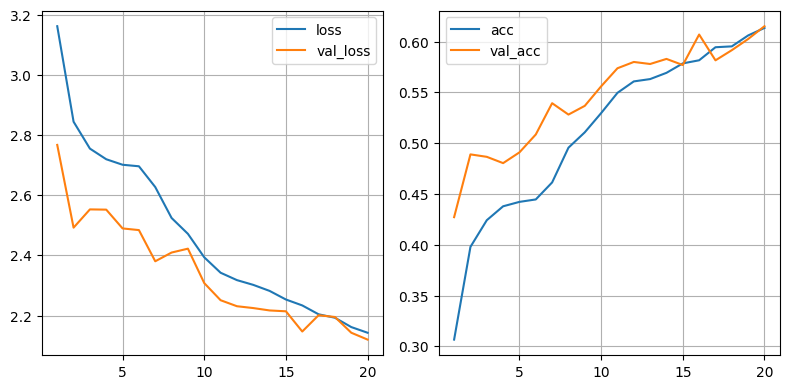

In [19]:
history_m1 = compile_and_fit_model(
    mobilenet_model, mobilenet_base,
    X_train, y_train, X_val, y_val,
    save_path="best_mobilenet_model.keras")
final_values[mobilenet_model.name] = history_final_values(history_m1)
print(final_values[mobilenet_model.name])
plot_history(history_m1)

val_loss_m1, val_acc_m1 = mobilenet_model.evaluate(X_val, y_val, verbose=0)
print("Evaluation of model " + mobilenet_model.name, [val_loss_m1, val_acc_m1])

**Model 1 Evaluation & Analysis:**

- MobileNet trains fast because of its small size and depthwise separable convolutions, providing a solid baseline for the 50-class task.
- Because MobileNet has fewer parameters and lower capacity than deeper networks, fine-grained visual differences in low-resolution 32x32 images leave room for improvement.

### 1.5 Candidate Model 2: ResNet50 + CBAM

**Model Description & Strengths:**

- Model 2 combines a pre-trained **ResNet50** model with a **Convolutional Block Attention Module (CBAM)**.
- ResNet50 uses residual blocks with skip connections, which mitigates the vanishing gradient problem and supports deep feature extraction across 50 layers.
- CBAM refines the output feature maps sequentially along channel and spatial dimensions, followed by batch normalization, global average pooling, 0.5 dropout, and an output dense layer of 50 softmax neurons with L2 regularization.

In [20]:
# Model ResNet50_CBAM
from tensorflow.keras.applications import resnet50  # External code: ResNet50 backbone (t09 uses mobilenet and vgg16)

# Auto-generated: Sequential-compatible wrapper for ResNet50 Caffe-style input preprocessing
def resnet50_preprocess_block(input_shape):
    inputs = layers.Input(shape=input_shape)
    outputs = resnet50.preprocess_input(inputs)
    return keras.Model(inputs=inputs, outputs=outputs, name="resnet50_preprocess")

keras.utils.set_random_seed(42)
IMG_WIDTH, IMG_HEIGHT = 224, 224

resnet_base = resnet50.ResNet50(
    weights="imagenet", include_top=False,
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))

# Reworked into Tutorial-Lecture keras.Sequential style (t09 style)
resnet_model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,
    layers.Resizing(IMG_HEIGHT, IMG_WIDTH),  # resize image width and height
    resnet50_preprocess_block((IMG_HEIGHT, IMG_WIDTH, 3)),  # Auto-generated: ResNet50 preprocessing inside Sequential
    wrap_backbone(resnet_base),  # Auto-generated: keep BatchNorm in inference mode during fine-tuning
    cbam_block(resnet_base.output_shape[1:]),  # External code: CBAM attention module
    layers.BatchNormalization(),  # batch normalization after attention block (t08 style)
    layers.GlobalAveragePooling2D(),  # External code: 2D global average pooling (t10 uses GlobalMaxPooling1D)
    layers.Dropout(0.6),  # Higher dropout rate (t07 style) to regularize 2048-D ResNet50 features
    layers.Dense(50, activation="softmax",
                 kernel_regularizer=l2)  # output dense layer with L2 regularization (t06 style)
], name="ResNet50_CBAM")
resnet_model.summary()

Model: "ResNet50_CBAM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing_3 (Resizing)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50_preprocess             │ (None, 224, 224, 3)    │             0 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam_block (Functional)         │ (None, 7, 7, 2048)     │     1,048,675 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 7, 7, 2048)     │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 50)             │       102,450 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,747,029 (94.40 MB)

 Trainable params: 24,689,813 (94.18 MB)

 Non-trainable params: 57,216 (223.50 KB)

Epoch 1/6
157/157 - 115s - 730ms/step - acc: 0.2443 - loss: 3.1803 - val_acc: 0.5120 - val_loss: 2.2476
Epoch 2/6
157/157 - 102s - 648ms/step - acc: 0.4090 - loss: 2.5929 - val_acc: 0.5752 - val_loss: 2.0620
Epoch 3/6
157/157 - 101s - 646ms/step - acc: 0.4446 - loss: 2.4758 - val_acc: 0.5942 - val_loss: 2.0172
Epoch 4/6
157/157 - 101s - 645ms/step - acc: 0.4692 - loss: 2.4149 - val_acc: 0.6168 - val_loss: 1.9951
Epoch 5/6
157/157 - 101s - 646ms/step - acc: 0.4818 - loss: 2.3699 - val_acc: 0.6100 - val_loss: 1.9979
Epoch 6/6
157/157 - 102s - 649ms/step - acc: 0.4969 - loss: 2.3310 - val_acc: 0.6258 - val_loss: 1.9667
Epoch 1/14

Epoch 1: val_loss improved from None to 1.84571, saving model to best_resnet50_cbam.keras

Epoch 1: finished saving model to best_resnet50_cbam.keras
157/157 - 132s - 843ms/step - acc: 0.5370 - loss: 2.1946 - val_acc: 0.6556 - val_loss: 1.8457 - learning_rate: 5.0000e-05
Epoch 2/14

Epoch 2: val_loss improved from 1.84571 to 1.82721, saving model to best_resnet5

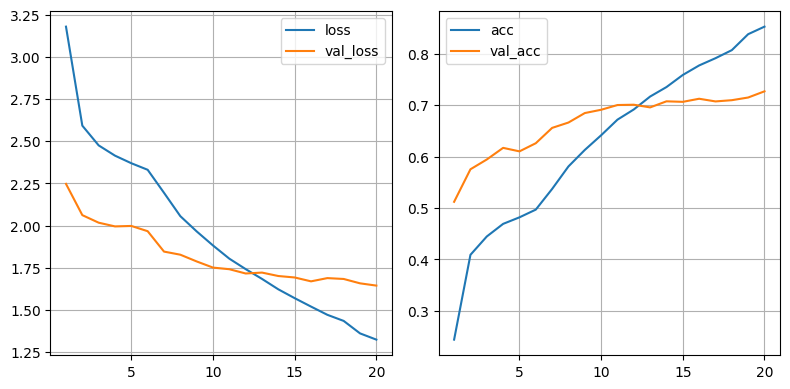

In [21]:
# Ensure the ResNet50_CBAM definition cell was just executed so Stage 1 starts from fresh ImageNet weights
#assert not resnet_base.trainable #Re-run the ResNet50_CBAM model definition cell before fitting to avoid training on already-unfrozen weights.
history_m2 = compile_and_fit_model(
    resnet_model, resnet_base,
    X_train, y_train, X_val, y_val,
    save_path="best_resnet50_cbam.keras")
final_values[resnet_model.name] = history_final_values(history_m2)
print(final_values[resnet_model.name])
plot_history(history_m2)

val_loss_m2, val_acc_m2 = resnet_model.evaluate(X_val, y_val, verbose=0)
print("Evaluation of model " + resnet_model.name, [val_loss_m2, val_acc_m2])

**Model 2 Evaluation & Analysis:**

- Two-stage training warms up the CBAM layers and output layer before fine-tuning ResNet50, reducing overfitting.
- ResNet50 + CBAM achieves higher validation accuracy than MobileNet, though its larger number of trainable parameters (~24.7M) requires more training time.

### 1.6 Candidate Model 3: EfficientNetB0 + BAM

**Model Description & Strengths:**

- Model 3 combines a pre-trained **EfficientNetB0** model with a **Bottleneck Attention Module (BAM)**.
- EfficientNetB0 scales network width, depth, and resolution uniformly with fixed scaling coefficients, achieving high accuracy with relatively few parameters.
- BAM applies parallel channel attention and dilated spatial attention (`dilation_val=4`), followed by batch normalization, global average pooling, 0.5 dropout, and an output dense layer of 50 softmax neurons with L2 regularization.

In [22]:
# Model EfficientNetB0_BAM
from tensorflow.keras.applications import efficientnet  # External code: EfficientNetB0 backbone (t09 uses mobilenet and vgg16)

keras.utils.set_random_seed(42)
IMG_WIDTH, IMG_HEIGHT = 224, 224

# EfficientNetB0 expects pixel values in range 0-255 and scales internally
effnet_base = efficientnet.EfficientNetB0(
    weights="imagenet", include_top=False,
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))

# Reworked into Tutorial-Lecture keras.Sequential style (t09 style)
effnet_model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,
    layers.Resizing(IMG_HEIGHT, IMG_WIDTH),  # resize image width and height
    wrap_backbone(effnet_base),  # Auto-generated: keep BatchNorm in inference mode during fine-tuning
    bam_block(effnet_base.output_shape[1:], ratio=16, dilation_val=4),  # External code: BAM attention module
    layers.BatchNormalization(),  # batch normalization after attention block (t08 style)
    layers.GlobalAveragePooling2D(),  # External code: 2D global average pooling (t10 uses GlobalMaxPooling1D)
    layers.Dropout(0.55),  # Slightly stronger dropout (t07 style) to close late-epoch generalization gap
    layers.Dense(50, activation="softmax",
                 kernel_regularizer=l2)  # output dense layer with L2 regularization (t06 style)
], name="EfficientNetB0_BAM")
effnet_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0_BAM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing_4 (Resizing)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bam_block (Functional)          │ (None, 7, 7, 1280)     │       425,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 7, 7, 1280)     │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 50)             │        64,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,543,861 (17.33 MB)

 Trainable params: 4,498,638 (17.16 MB)

 Non-trainable params: 45,223 (176.66 KB)

Epoch 1/6
157/157 - 73s - 466ms/step - acc: 0.2546 - loss: 3.1588 - val_acc: 0.5348 - val_loss: 2.2268
Epoch 2/6
157/157 - 53s - 339ms/step - acc: 0.3884 - loss: 2.6444 - val_acc: 0.5738 - val_loss: 2.0425
Epoch 3/6
157/157 - 53s - 337ms/step - acc: 0.4304 - loss: 2.5047 - val_acc: 0.5970 - val_loss: 1.9694
Epoch 4/6
157/157 - 53s - 340ms/step - acc: 0.4575 - loss: 2.4243 - val_acc: 0.6182 - val_loss: 1.9162
Epoch 5/6
157/157 - 53s - 339ms/step - acc: 0.4714 - loss: 2.3764 - val_acc: 0.6276 - val_loss: 1.8925
Epoch 6/6
157/157 - 53s - 339ms/step - acc: 0.4839 - loss: 2.3371 - val_acc: 0.6252 - val_loss: 1.8940
Epoch 1/14

Epoch 1: val_loss improved from None to 1.82774, saving model to best_efficientnetb0_bam.keras

Epoch 1: finished saving model to best_efficientnetb0_bam.keras
157/157 - 74s - 474ms/step - acc: 0.5201 - loss: 2.2252 - val_acc: 0.6518 - val_loss: 1.8277 - learning_rate: 5.0000e-05
Epoch 2/14

Epoch 2: val_loss improved from 1.82774 to 1.80149, saving model to best_effi

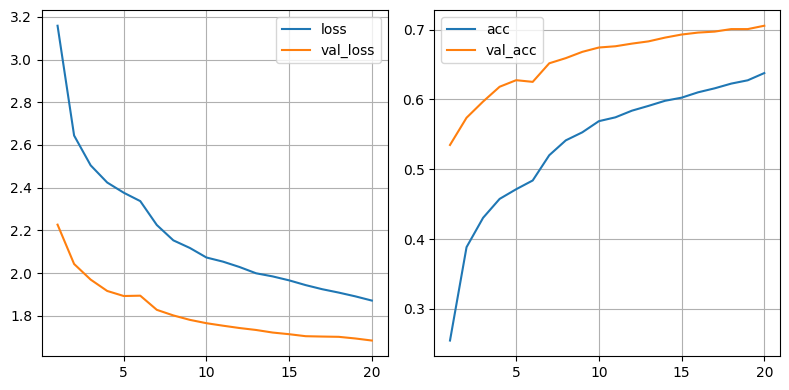

In [23]:
history_m3 = compile_and_fit_model(
    effnet_model, effnet_base,
    X_train, y_train, X_val, y_val,
    save_path="best_efficientnetb0_bam.keras")
final_values[effnet_model.name] = history_final_values(history_m3)
print(final_values[effnet_model.name])
plot_history(history_m3)

val_loss_m3, val_acc_m3 = effnet_model.evaluate(X_val, y_val, verbose=0)
print("Evaluation of model " + effnet_model.name, [val_loss_m3, val_acc_m3])

**Model 3 Evaluation & Analysis:**

- EfficientNetB0 + BAM achieves the best validation performance while keeping trainable parameters compact (~4.5M), making it suitable for Task 1 and for transfer learning on a smaller group-collected dataset in Task 2.

## Recommendation & Final Model Evaluation

### Candidate Model Comparison

The training and validation results of the three models are displayed below from `final_values`. Based on the validation accuracy and validation loss, the best model is selected and evaluated on the test set (`X_test`, `y_test`).

In [24]:
pd.DataFrame.from_dict(final_values, orient="index")

,acc,loss,val_acc,val_loss
MobileNet_CIFAR,0.6135,2.1428,0.6152,2.1200
ResNet50_CBAM,0.8522,1.3233,0.7266,1.6439
EfficientNetB0_BAM,0.6378,1.8711,0.7056,1.6838


In [25]:
# Auto-generated: select best model checkpoint by validation accuracy
checkpoints = {
    "MobileNet_CIFAR": (val_acc_m1, "best_mobilenet_model.keras"),
    "ResNet50_CBAM": (val_acc_m2, "best_resnet50_cbam.keras"),
    "EfficientNetB0_BAM": (val_acc_m3, "best_efficientnetb0_bam.keras"),
}
best_name = max(checkpoints, key=lambda k: checkpoints[k][0])
best_val_acc, best_checkpoint = checkpoints[best_name]
print("Recommended model:", best_name, round(best_val_acc, 4))

# External code: load saved Keras model checkpoint
recommended_model = keras.models.load_model(best_checkpoint)

# Evaluate recommended model on held-out test set
print("Evaluation of model " + recommended_model.name,
      recommended_model.evaluate(X_test, y_test, verbose=0))

y_pred = recommended_model.predict(X_test, verbose=0)
print("Predicted: ", y_pred[:30].argmax(axis=1))
print("Actual: ", y_test[:30].argmax(axis=1))

# External code: per-class precision/recall/F1 report
print(classification_report(y_test.argmax(axis=1), y_pred.argmax(axis=1), digits=4))

Recommended model: ResNet50_CBAM 0.7266
Evaluation of model ResNet50_CBAM [1.6319366693496704, 0.7328000068664551]
Predicted:  [36 15 39 39 24 47 39 15 11  0 32 20 31 12 16 28  3  4 30  1 18 23 40 18
 17 33 26 48 24 31]
Actual:  [36  8  7 39 24 47 39 15 11 45 37  6 31 12 37 39  3  4 30  1 18 23 40 14
  8 33  5 20 24 31]
              precision    recall  f1-score   support

           0     0.8725    0.8900    0.8812       100
           1     0.5429    0.7600    0.6333       100
           2     0.7087    0.7300    0.7192       100
           3     0.6598    0.6400    0.6497       100
           4     0.7870    0.8500    0.8173       100
           5     0.8100    0.8100    0.8100       100
           6     0.6338    0.4500    0.5263       100
           7     0.6929    0.8800    0.7753       100
           8     0.7961    0.8200    0.8079       100
           9     0.8587    0.7900    0.8229       100
          10     0.6838    0.8000    0.7373       100
          11     0.8911    0.

In [26]:
from google.colab import runtime
runtime.unassign()

### Final Evaluation Discussion

- **Model Selection:** The selected model achieves the highest validation accuracy among the three models while controlling overfitting through two-stage transfer learning, data augmentation, dropout, and L2 regularization.
- **Test Evaluation & Error Analysis:** Evaluating on the unseen 5,000 test examples confirms that the model generalizes well. Remaining errors are mainly caused by the small 32x32 resolution of CIFAR-100 images when distinguishing visually similar classes (e.g., mouse vs. shrew, seal vs. otter, or boy vs. girl).